<table style="width: 100%;">
  <tr>
    <td style="text-align: left; vertical-align: middle;">
        <h1 style="margin: 0;">Deep Learning's Assignment 4</h1>
        <h4 style="margin: 0;">Prof. Bahrak</h4>
        <h4 style="margin: 0;">Authors: Erfan Ahmadi, Mohammad Ali Olama</h4>
        <h4 style="margin: 0;">[Group work]</h4>
    </td>
    <td style="text-align: right; vertical-align: middle;">
      <img src="https://media.porsline.ir/images/1642313491sktwifppujekhvh" alt="CC" width="1000">
    </td>
  </tr>
</table>



# Question 2

## Libraries and imports


In [1]:
!pip install transformers peft datasets accelerate scipy bitsandbytes wandb  -qqq

In [2]:
!huggingface-cli login --token YOUR_HF_TOKEN

The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `huggingface-cli` if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `LLM-HW1` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
The current active token is: `LLM-HW1`


In [3]:
!pip install trl

In [4]:
import torch
import numpy as np
import re
import time
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer,AutoModelForCausalLM

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

## Constant variables
to make the code more readable, we define constant variables that will be used across the code in this Config class:

In [7]:
class CONFIG:
    seed = 42
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model_name = "gpt2"
    dataset_name = "imdb"

    train_data_size = 5000
    test_data_size = 1000
    val_data_size = 1000

    train_batch_size = 32
    gradient_accumulation_steps = 2
    epochs = 10

    # LoRA Configs
    lora_rank = 16
    lora_alpha = 32
    use_gradient_checkpointing = "unsloth"
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj"]

device = CONFIG.device

## Q2.1


### 1. How does the unidirectional attention-based architecture in GPT work?

GPT uses a unidirectional (also called causal) attention mechanism. This means each token in a sequence can only attend to tokens that come before it (i.e., left-to-right context). This structure ensures that the model cannot "see the future" and is aligned with its goal of predicting the next word in a sequence. During training, the model learns to estimate the probability of the next word given all previous words, enabling it to generate coherent and contextually appropriate text.

---




### 2. What are the key differences between the GPT and BERT architectures?

| Feature               | GPT                                      | BERT                                      |
|-----------------------|------------------------------------------|-------------------------------------------|
| Attention Direction   | Unidirectional (left-to-right)           | Bidirectional (both directions)           |
| Model Architecture    | Transformer decoder-only                     | Transformer encoder-only                       |
| Pretraining Task      | Language modeling (next word prediction) | Masked language modeling                  |
| Fine-tuning Approach  | Few-shot or zero-shot prompting (GPT-3)  | Task-specific fine-tuning                 |
| Output Generation     | Generative                               | Discriminative                            |

GPT is primarily generative, making it suitable for tasks like text generation. BERT is better at understanding and classification tasks due to its bidirectional context.

---



### 3. How are pretraining and fine-tuning performed in GPT?

**Pretraining:**  
GPT is pretrained on a large corpus of text using an autoregressive language modeling objective. It learns to predict the next token in a sequence given the previous tokens, enabling the model to capture linguistic patterns, grammar, and factual knowledge.

**Fine-tuning:**  
- In earlier GPT models, task-specific fine-tuning was performed using labeled datasets by adding output layers and training on the target task.
- In GPT-3, the model is not fine-tuned in the traditional sense. Instead, it is used in a **few-shot**, **one-shot**, or **zero-shot** manner by providing examples or instructions in the input prompt. This approach leverages the model’s massive pretraining to perform new tasks without gradient updates.

---

## Q2.2

first, let's download the dataset.

In [8]:
from datasets import load_dataset

dataset = load_dataset(CONFIG.dataset_name)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


### Part A
To analyze the dataset, we define a utility funtion to show the min, max, avg, and median of word count and character count of texts in that dataset. Besides, it will plot three charts, showing the distribution of word and char counts and histogram of labels. Finally, it will print some random examples from that dataset.

In [9]:
def analyze_dataset(dataset, num_samples=5):

    # Calculate text lengths
    text_lengths = [len(text) for text in dataset['text']]

    # Basic statistics
    min_length = min(text_lengths)
    max_length = max(text_lengths)
    avg_length = np.mean(text_lengths)
    median_length = np.median(text_lengths)

    print(f"Minimum text length: {min_length}")
    print(f"Maximum text length: {max_length}")
    print(f"Average text length: {avg_length}")
    print(f"Median text length: {median_length}")
    print(80 * "-")


    # same calculations for word count
    text_words = [len(text.split()) for text in dataset['text']]
    min_words = min(text_words)
    max_words = max(text_words)
    avg_words = np.mean(text_words)
    median_words = np.median(text_words)
    print(f"Minimum word count: {min_words}")
    print(f"Maximum word count: {max_words}")
    print(f"Average word count: {avg_words}")
    print(f"Median word count: {median_words}")

    # Plot text length distribution
    plt.figure(figsize=(10, 6))
    plt.hist(text_lengths, bins=100)
    plt.xlabel("Text Length")
    plt.ylabel("Frequency")
    # plt.yscale('log')
    plt.title("Distribution of Text Lengths")
    plt.show()

    # Plot text word count distribution
    plt.figure(figsize=(10, 6))
    plt.hist(text_words, bins=100)
    plt.xlabel("Text Words")
    plt.ylabel("Frequency")
    # plt.yscale('log')
    plt.title("Distribution of Text Words count")
    plt.show()

    # distribution of labels and count as text n each bar
    data_label = dataset['label']

    # Create a histogram
    counts, bins, patches = plt.hist(data_label, bins=[-0.5, 0.5, 1.5], edgecolor='black', rwidth=0.6)
    for count, patch in zip(counts, patches):
        x = patch.get_x() + patch.get_width() / 2
        y = patch.get_height() / 2
        plt.text(x, y, str(int(count)), ha='center', va='center', color='white', fontsize=12)

    plt.xticks([0, 1])
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.title('Histogram of labels')
    plt.show()


    # Display random samples
    print("\nRandom Samples:")
    random_indices = np.random.choice(len(dataset), size=num_samples, replace=False)
    for i in random_indices:
        print(f"Sample {i+1}:\n{dataset['text'][i]}\n")




Minimum text length: 52
Maximum text length: 13704
Average text length: 1325.06964
Median text length: 979.0
--------------------------------------------------------------------------------
Minimum word count: 10
Maximum word count: 2470
Average word count: 233.7872
Median word count: 174.0


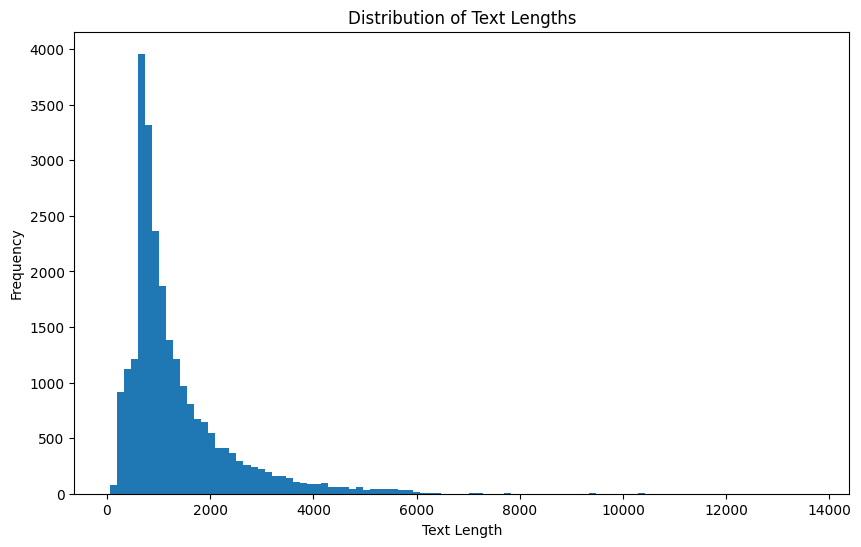

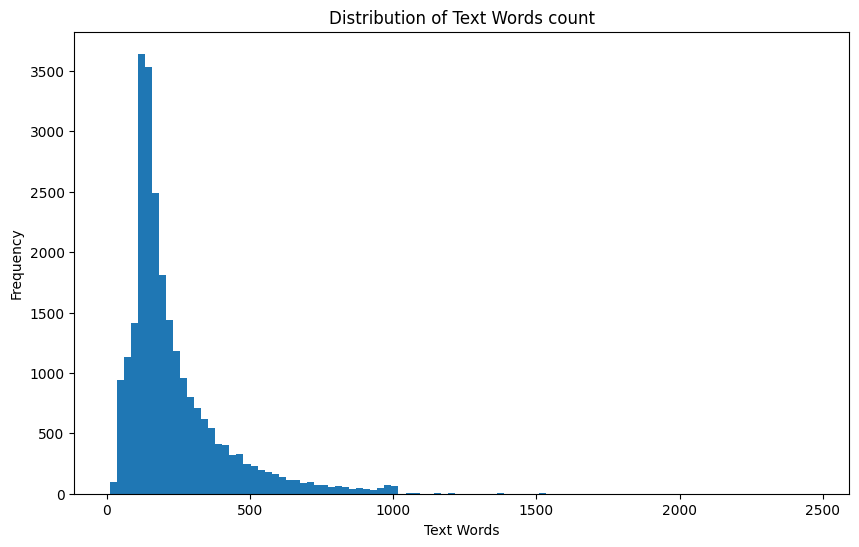

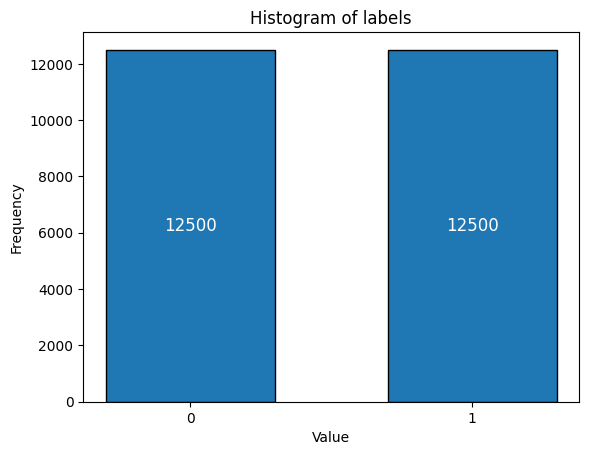


Random Samples:
Sample 6869:
Dumb is as dumb does, in this thoroughly uninteresting, supposed black comedy. Essentially what starts out as Chris Klein trying to maintain a low profile, eventually morphs into an uninspired version of "The Three Amigos", only without any laughs. In order for black comedy to work, it must be outrageous, which "Play Dead" is not. In order for black comedy to work, it cannot be mean spirited, which "Play Dead" is. What "Play Dead" really is, is a town full of nut jobs. Fred Dunst does however do a pretty fair imitation of Billy Bob Thornton's character from "A Simple Plan", while Jake Busey does a pretty fair imitation of, well, Jake Busey. - MERK

Sample 24017:
I dug out from my garage some old musicals and this is another one of my favorites. It was written by Jay Alan Lerner and directed by Vincent Minelli. It won two Academy Awards for Best Picture of 1951 and Best Screenplay. The story of an American painter in Paris who tries to make it big. Nina Foc

In [10]:
analyze_dataset(dataset['train'])

Minimum text length: 32
Maximum text length: 12988
Average text length: 1293.7924
Median text length: 962.0
--------------------------------------------------------------------------------
Minimum word count: 4
Maximum word count: 2278
Average word count: 228.52668
Median word count: 172.0


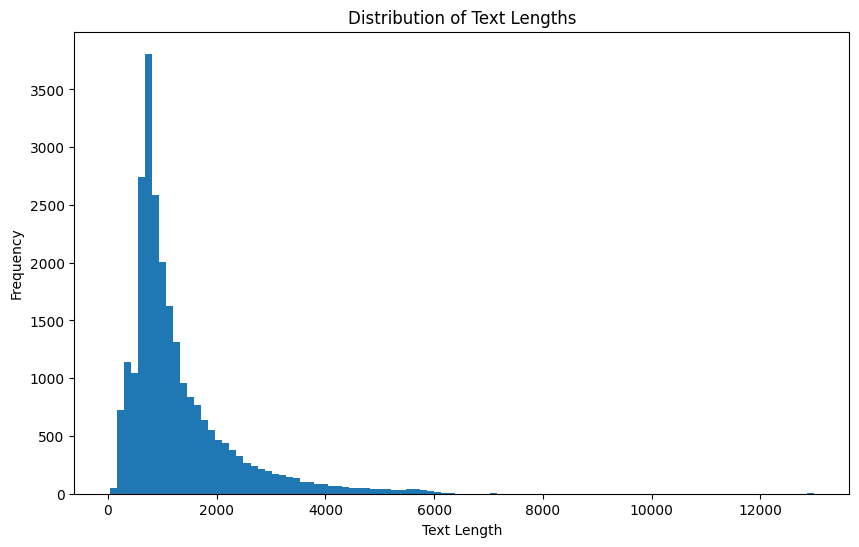

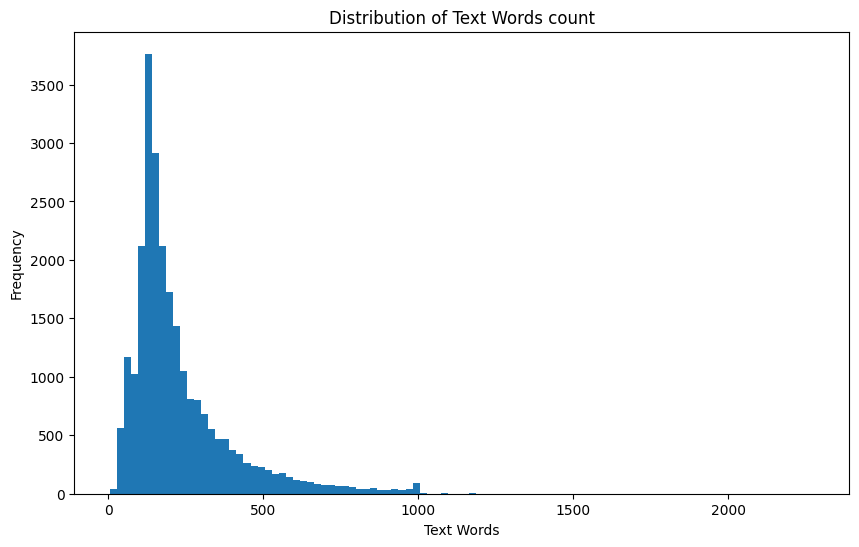

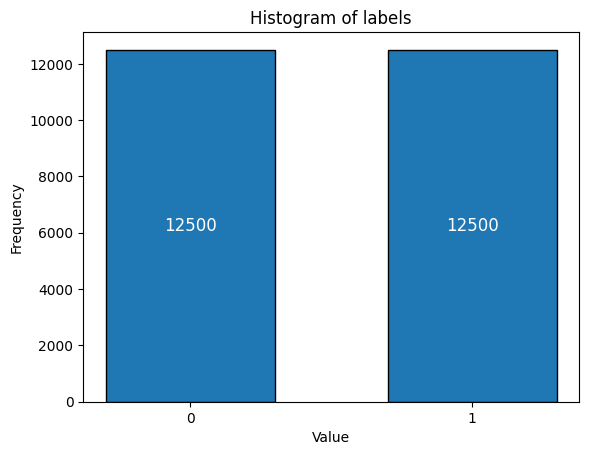


Random Samples:
Sample 17424:
When I was a kid, I loved "Tiny Toons". I especially loved "Tiny Toons: How I spent my Summer Vacation". I thought it was laughs on the floor funny. A few years later, my friend had the video. And I figured I'd watch it for the good old days. I was still on the floors laughing. My opinion, the Plucky and Hampton skit is the best. They decide to go to "Happy World Land". And they end up having a crazy adventure to get there. All the skits are funny. I'm still looking for the video. So, if anyone has any tips. Please write me. <br /><br />This is one of the funniest cartoons I have ever seen.<br /><br />10/10

Sample 14442:
Rock Star is a "nice" movie. Everyone is nice. Even the guys who aren't supposed to be nice, really are nice. Chris is a nice guy, who learns a lesson in life. He goes back to his girlfriend Emily, who is also nice. <br /><br />It's a good movie, despite all the niceness. Maybe I'm just used to all the angst of the X Gen music. In some w

In [11]:
analyze_dataset(dataset['test'])

#### Filter long texts

In order to speedup the training process, we will only use a fixed range of text lengths. This will affect the `max_new_tokens` in the following sections.

In [12]:
def filter_long_texts(example):
    return len(example['text']) >= 500 and len(example['text']) <= 1000

train_dataset = dataset['train'].filter(filter_long_texts)
test_dataset = dataset['test'].filter(filter_long_texts)

In [13]:
train_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 10457
})

In [14]:
test_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 10580
})

Again, analyze the datasets.

Minimum text length: 500
Maximum text length: 1000
Average text length: 759.3708520608205
Median text length: 747.0
--------------------------------------------------------------------------------
Minimum word count: 76
Maximum word count: 296
Average word count: 136.49660514487903
Median word count: 135.0


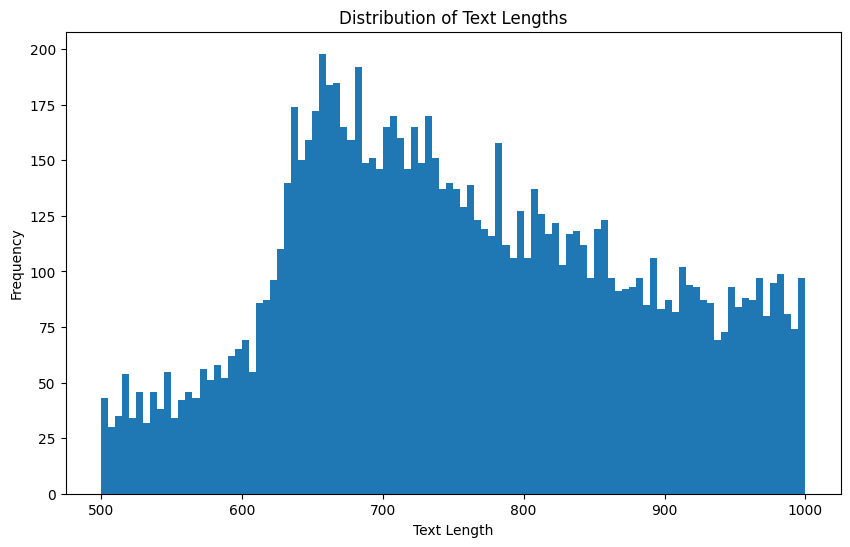

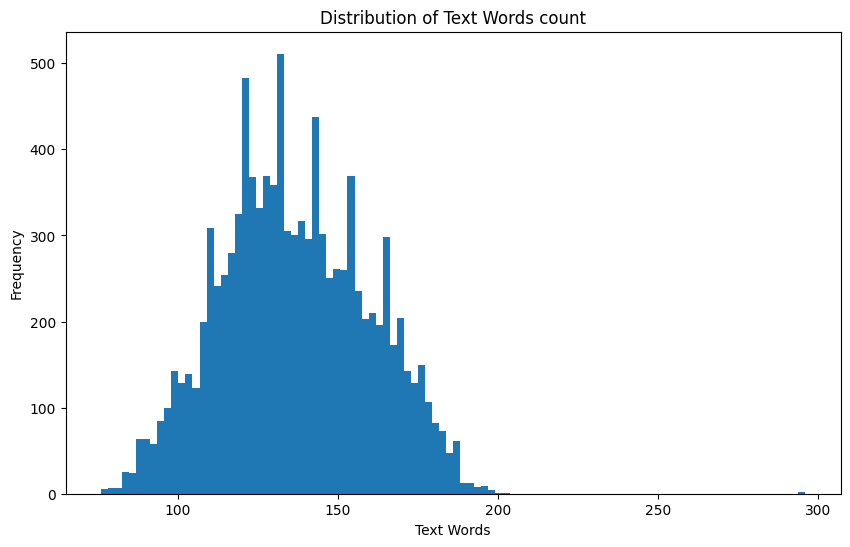

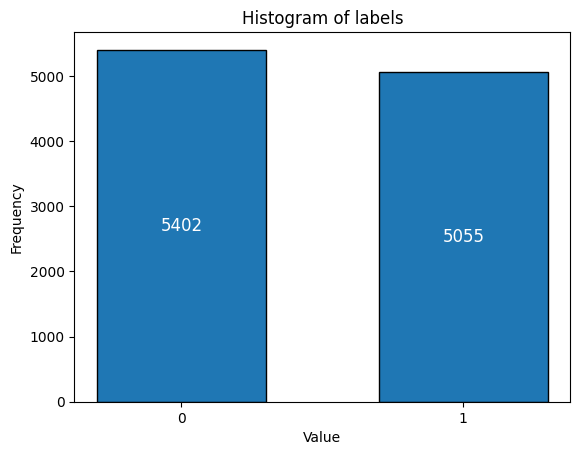


Random Samples:
Sample 6931:
Now this is more like it! The first movie had some iffy dialogue and some weaker acting, but it seems like the team behind this got their stuff together for the sequel and put out a solid, thoroughly enjoyable, hilarious and creative comedy that will keep everyone on the edge of their seats the whole way through.<br /><br />Seriously, this is just full of great stuff, brimming with creativity, and it's less of a spoof on 80s movies at the same time. The scenes in Hell are great, and so are the ones in Heaven. There's really no shortage to the mad-cap adventurous romp that this one promises, and you will never see another movie like this. Even the hammy final act of the movie isn't as bad as the first one, being generally heartwarming and enjoyable in its extremely cliché repertoire of family fun movie bliss. And even Keanu Reeves, despite looking about 30, isn't that bad here.<br /><br />Sounds like a good deal to me.

Sample 2550:
Lesbian vampire film abo

In [15]:
analyze_dataset(train_dataset)

Minimum text length: 500
Maximum text length: 1000
Average text length: 758.5769376181474
Median text length: 746.0
--------------------------------------------------------------------------------
Minimum word count: 55
Maximum word count: 210
Average word count: 136.53950850661624
Median word count: 135.0


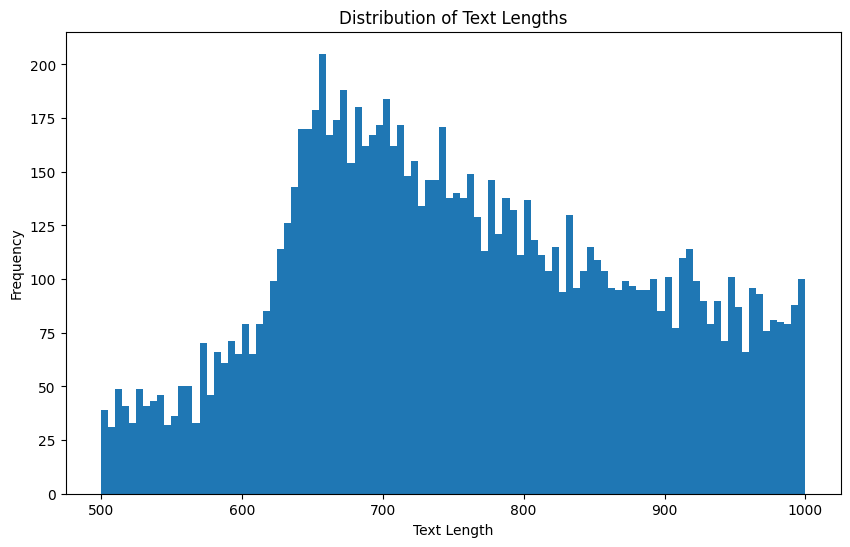

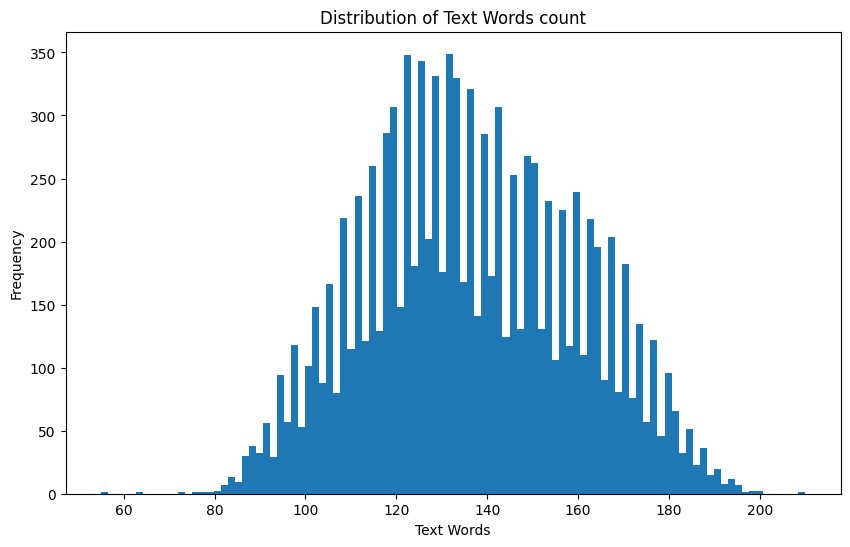

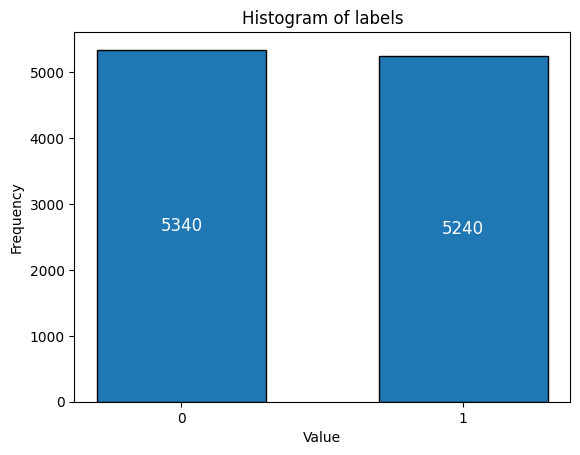


Random Samples:
Sample 4918:
Swoon focuses on Leopold and Loeb's homosexual relationship - a facet of the case that has been mostly (and unjustly) ignored since their trial, even by Leopold himself in his autobiography. But, even in its treatment of this Swoon over does it by far. Worse, it twists, combines, and straight out alters the details of the case which will irritate anyone who knows much about it while at the same time managing to confuse those who are not familiar with it. While it is an interestingly made film, Swoon stinks.<br /><br />1 out of 10 - awful.

Sample 49:
I`m in two minds about FOLLOWING , the film debut of Christopher Nolan . Part of me admires it for costing 6,000 dollars to make but part of me hates it for being too art house . In many ways it reminds me of the cult movie PI , a film I disliked , and I can`t get my head around the central plot of a man who wants to be writer following people around . Wouldn`t it be more logical for someone wanting to be a wr

In [16]:
analyze_dataset(test_dataset)

Now, we sample from test and train datasets randomly. Also, create a validation dataset for training purpose.

In [17]:
train_dataset = train_dataset.shuffle(seed=CONFIG.seed).select(range(CONFIG.train_data_size))
test_dataset = test_dataset.shuffle(seed=CONFIG.seed).select(range(CONFIG.test_data_size+ CONFIG.val_data_size))
validation_dataset = test_dataset.select(range(CONFIG.test_data_size, CONFIG.test_data_size + CONFIG.val_data_size))
test_dataset = test_dataset.select(range(CONFIG.test_data_size))


In [18]:
test_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 1000
})

In [19]:
validation_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 1000
})

In [20]:
train_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 5000
})

Minimum text length: 500
Maximum text length: 1000
Average text length: 759.4886
Median text length: 748.0
--------------------------------------------------------------------------------
Minimum word count: 76
Maximum word count: 296
Average word count: 136.4094
Median word count: 135.0


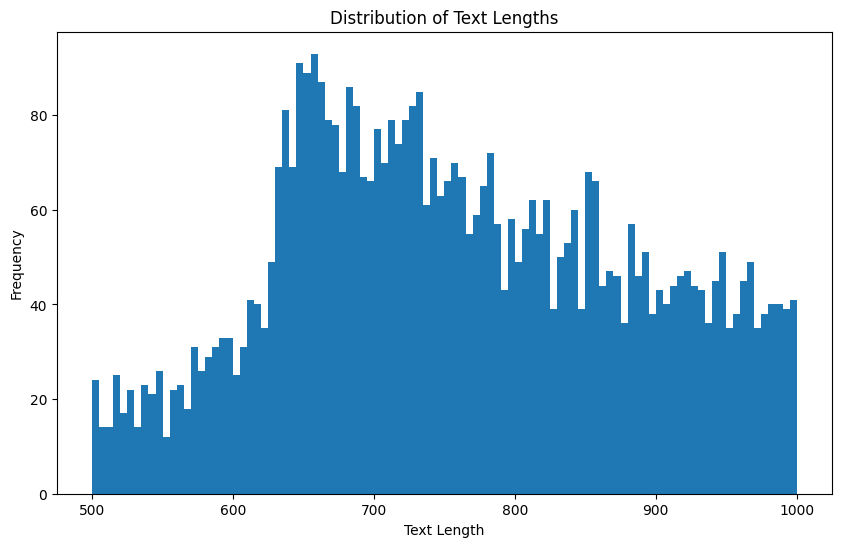

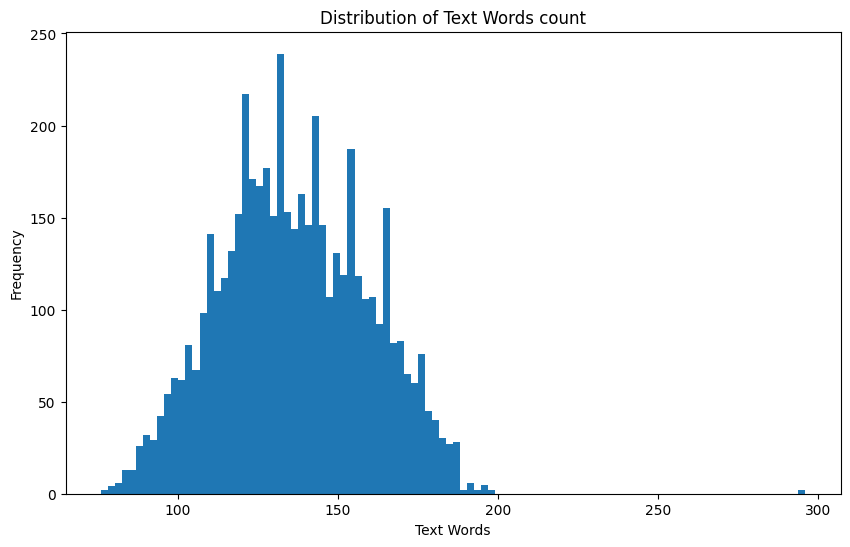

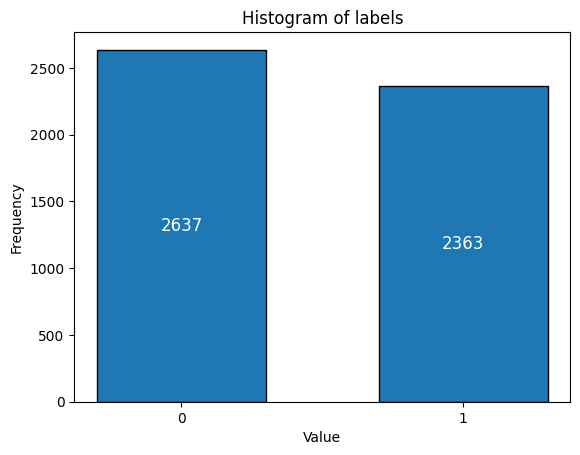


Random Samples:
Sample 730:
The worst movie I have seen in quite a while. Interesting first half with some engaging, terse dialogue among dubious characters in a late-night bar. The movie then degenerates into a shapeless succession of scenes aiming for visual shock (read disgust) without any redeeming observations or lessons in humanity or anything else.<br /><br />I wanted to walk out, but the director was present at this showing and my politeness preventing me from showing him disrespect. Still, time is precious (as the director himself observed in his intro) and I really begrudge the time I wasted on the second half of this one.<br /><br />Saving graces were the three main characters in the first half of the movie, especially the female lead.

Sample 1341:
This movie is very very very poor. I have seen better movies. <br /><br />There was a bit of tension but not much to make you jump out of your chair. It begins slowly with the building of tension. Which is not a success. At leas

In [21]:
analyze_dataset(train_dataset)

Minimum text length: 500
Maximum text length: 1000
Average text length: 755.167
Median text length: 746.0
--------------------------------------------------------------------------------
Minimum word count: 82
Maximum word count: 198
Average word count: 135.977
Median word count: 134.5


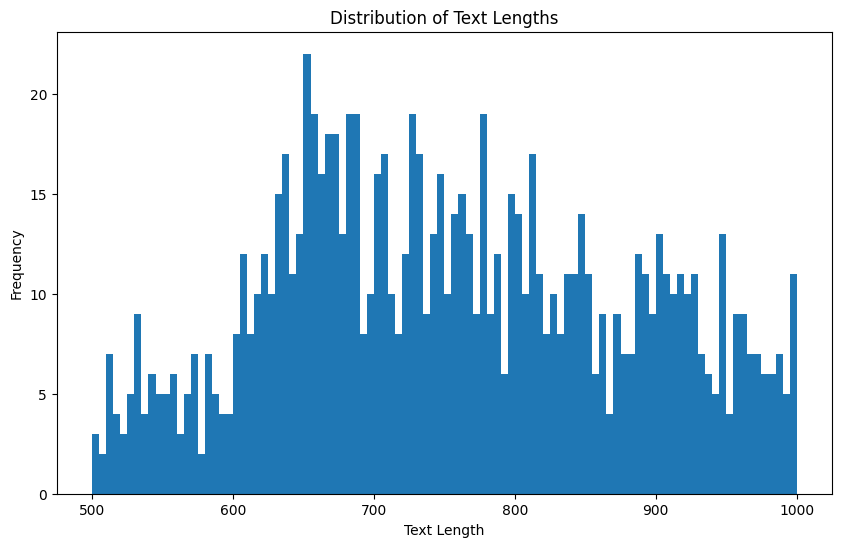

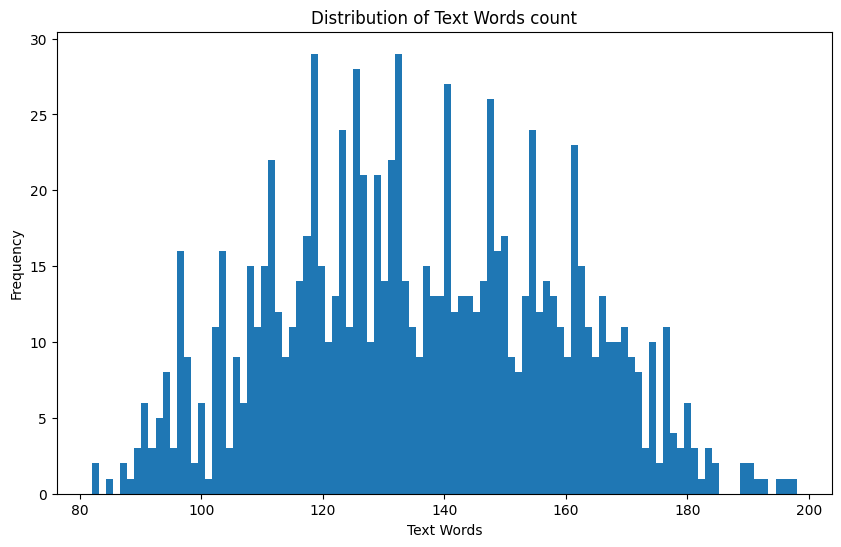

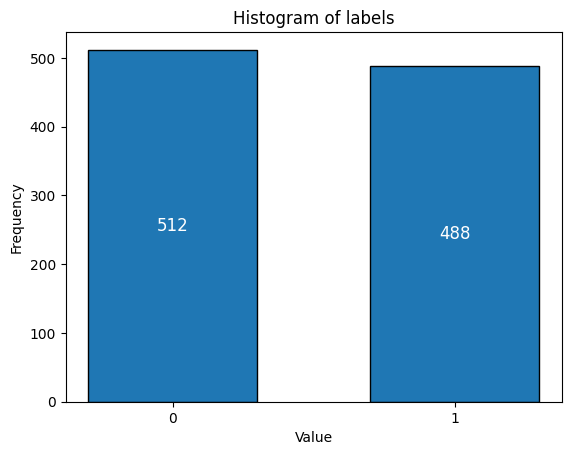


Random Samples:
Sample 990:
*Minor Spoiler* <br /><br />Inhabited isn't scary, but it is creepy. It is an interesting 'little' story with good acting and great special effects makeup.<br /><br />Basic plot: A little girl blames the strange things going on at her family's new house and accompanying playhouse on her faerie friends.<br /><br />The movie doesn't waste time getting moving, though the ending could have been more involved.<br /><br />I don't recommend this movie to those expecting/wanting hardcore horror, but I do recommend it to those who want a chiller and not necessarily a thriller.

Sample 698:
the movie is simply horrible (2/10). Although actors are trying their best (well sometimes that isn't much) special effects are ...let me put it this way it would be better if there weren't any.<br /><br />The script is based on Sapkowski's prose, so it should be the biggest advantage of this movie. Sadly it's the opposite. There is nothing left of the original atmosphere. And it'

In [22]:
analyze_dataset(test_dataset)

Minimum text length: 501
Maximum text length: 1000
Average text length: 759.745
Median text length: 749.0
--------------------------------------------------------------------------------
Minimum word count: 82
Maximum word count: 195
Average word count: 136.964
Median word count: 135.0


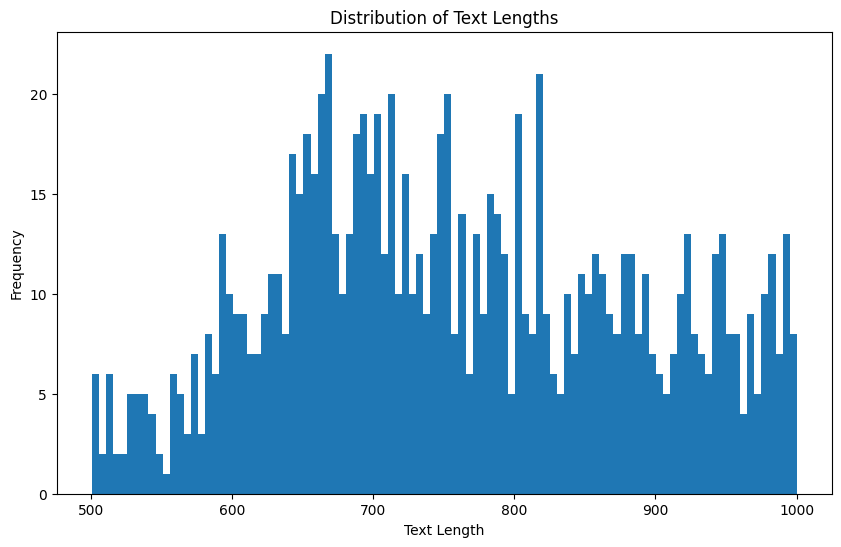

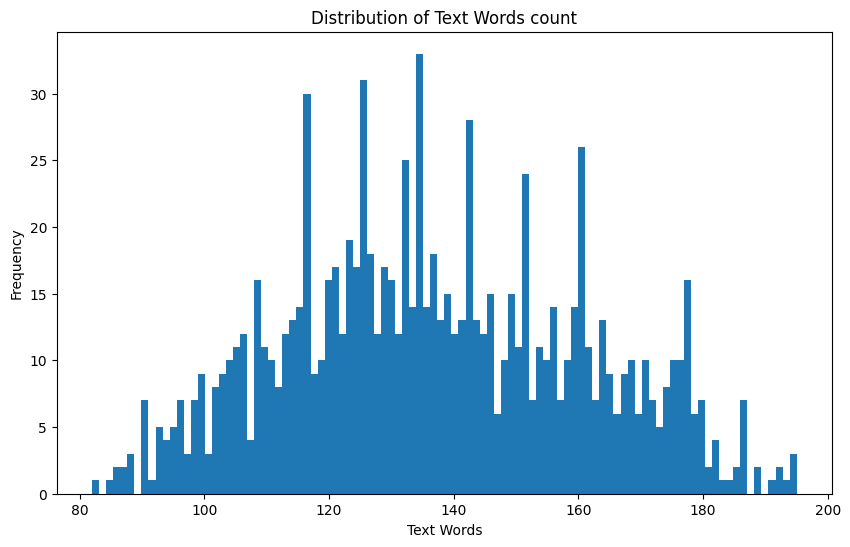

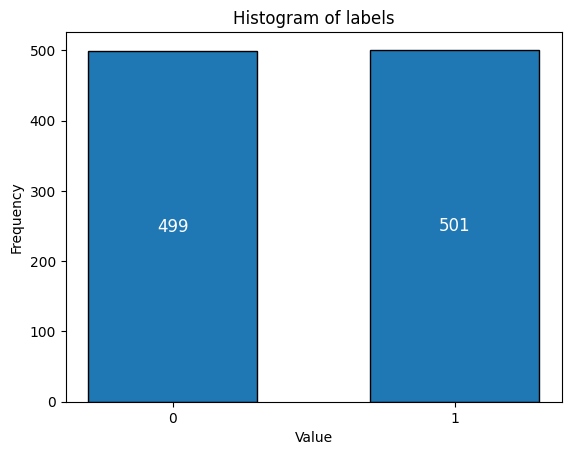


Random Samples:
Sample 925:
"Scarecrow Gone Wild: He's the Death of the Party!" Need I say more? Scarecrow gone wild got four out of ten stars from me for one simple reason: aside from the terrible acting, plot holes, cheap special effects, and anti-climactic whistling, it was cinematic gold! I think that this movie could have actually been really good, had the scarecrow turned out to be the baseball coach (as portrayed by the ever-so-brilliant Ken Shamrock). But then again, they would have had to cut those AWESOME "Return of the Jedi" electricity special effects.<br /><br />While watching this movie, my friends and I were convinced that it was in fact written by one of our friends, a stereotypical teen-aged boy. This movie has topless women, miserably fake gore, and dialog that could not have talked its way out of a paper bag, or in this case, a cornfield.<br /><br />If I could ask the filmmaker one thing, it would be this; "How much did you have to pay the teenager that wrote this f

In [23]:
analyze_dataset(validation_dataset)

### Part B
First, we will convert the labels to strings.(This won't be used!)

In [24]:

def convert_labels(example):
    # Create a new column 'sentiment' to store the string labels
    example['sentiment'] = 'positive' if example['label'] == 1 else 'negative'
    return example

train_dataset = train_dataset.map(convert_labels)
test_dataset = test_dataset.map(convert_labels)
validation_dataset = validation_dataset.map(convert_labels)


In [25]:
train_dataset[0]

{'text': 'I was living Rawlins when this movie was made and I got lucky enough to be able to work on it. Both as an extra and with Eddie Surkin on special effects. It was fun to see all the behind the scene workings, from the Barbedwire coming alive to the Electric chair up through the wardens office floor. Also it was a lot of fun getting to meet all the actors, from Viggo to Tiny. Also the gate that was cut into the prison wall for the movie was and still is called "Disney Gate" by locals. If anybody is interested and is ever in Rawlins, most of the movies sets are still in place and can be seen during the self guided tour. It was a lot of fun working for and with R. Harlin and wished I had a chance to do it again.',
 'label': 1,
 'sentiment': 'positive'}

The prompt format will be defined and used in following sections.

### Part C

Let's load the tokenizer.

In [26]:
from transformers import GPT2Tokenizer

tokenizer = GPT2Tokenizer.from_pretrained(CONFIG.model_name)
tokenizer.pad_token = tokenizer.eos_token


### Part D
This part is done in part B when we shuffle and sample the dataset.

## Q2.3

Let's load the model.

In [27]:
from transformers import GPT2ForSequenceClassification

model = GPT2ForSequenceClassification.from_pretrained(
    CONFIG.model_name,
    pad_token_id=tokenizer.eos_token_id,
    num_labels=2).to(device)

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [28]:
model

GPT2ForSequenceClassification(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (score): Linear(in_features=768, out_features=2, bias=False)
)

We don't want to do full-training. Rather, we prefer to freeze all layers of the model, except a few last layers.

In [29]:
# Freeze all model parameters
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the last transformer block
# GPT-2 has model.transformer.h which is a list of transformer blocks
# Let's unfreeze the last block (e.g., model.transformer.h[-1])
for param in model.transformer.h[-1].parameters():
    param.requires_grad = True

# Unfreeze the classification head
for param in model.score.parameters():  # `score` is the classification head in GPT2ForSequenceClassification
    param.requires_grad = True



In [30]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)


transformer.h.11.ln_1.weight
transformer.h.11.ln_1.bias
transformer.h.11.attn.c_attn.weight
transformer.h.11.attn.c_attn.bias
transformer.h.11.attn.c_proj.weight
transformer.h.11.attn.c_proj.bias
transformer.h.11.ln_2.weight
transformer.h.11.ln_2.bias
transformer.h.11.mlp.c_fc.weight
transformer.h.11.mlp.c_fc.bias
transformer.h.11.mlp.c_proj.weight
transformer.h.11.mlp.c_proj.bias
score.weight


Now, let's prepare our dataset. We should use tokenizer to tokenize the texts and create proper inputs for our model.


In [31]:
def prepare_data(example, tokenizer, ignore_index=-100):

    instruction_text = "Predict the sentiment in the following imdb review text. Valid sentiments are '1' (for positive) and '0' (for negative).\n"
    user_query = f"Review:{example['text']}\n"
    text=instruction_text+user_query
    tokenized_text = tokenizer(text, add_special_tokens=False, padding='max_length', truncation=True, max_length=512, return_tensors="pt")
    labels = example['label']

    return {
        "input_ids": tokenized_text["input_ids"].squeeze().tolist(),
        "attention_mask": tokenized_text["attention_mask"].squeeze().tolist(),
        "labels": labels}

In [32]:
# apply prepare_data on train_dataset

train_dataset1 = train_dataset.map(lambda example: prepare_data(example, tokenizer), batched=False , remove_columns=train_dataset.column_names)
validation_dataset1 = validation_dataset.map(lambda example: prepare_data(example, tokenizer), batched=False , remove_columns=train_dataset.column_names)
test_dataset1 = test_dataset.map(lambda example: prepare_data(example, tokenizer), batched=False , remove_columns=train_dataset.column_names)

In [33]:
train_dataset1

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 5000
})

To monitor the behavior of our training process, we create a custom callback:

In [34]:
from transformers import TrainerCallback
import math

class CustomCallback(TrainerCallback):
    def __init__(self, patience=3 , should_stop = False):
        self.patience = patience
        self.best_loss = float('inf')
        self.no_improvement_count = 0

    def on_step_end(self, args, state, control, **kwargs):
      if control.should_log and state.log_history:
        logs = state.log_history[-1]
        loss = logs.get("loss")
        if loss is not None:
            if loss < self.best_loss:
                self.best_loss = loss
                self.no_improvement_count = 0
            else:
                self.no_improvement_count += 1
                if self.no_improvement_count >= self.patience and should_stop:
                    control.should_training_stop = True

        if loss:
          perplexity = math.exp(loss)
          state.log_history[-1]["perplexity"] = perplexity # Add perplexity to the log
          print(f"Step: {state.global_step}, Loss: {loss:.4f}, Perplexity: {perplexity:.4f}, Best Loss: {self.best_loss:.4f}, Patience Counter: {self.no_improvement_count}")


In [35]:
train_dataset1.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
validation_dataset1.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
test_dataset1.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])


Moreover, to monitor the accuracy as a metric, we create a utility function:

In [36]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    return {"accuracy": acc, "f1": f1}


In [37]:
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/drive/MyDrive/TEIAS/Deep/HW4/res_gpt_new",
    per_device_train_batch_size=32,
    # gradient_accumulation_steps=2,
    learning_rate=3e-5,
    num_train_epochs=7,  # You can adjust this based on your needs
    warmup_ratio=0.1,
    group_by_length=True,
    lr_scheduler_type="cosine",

    logging_steps=50,  # Log training metrics every 10 steps
    # save_steps=50,  # Save model checkpoints every 100 steps
    save_strategy="epoch",
    eval_strategy="epoch",  # Evaluate during training
    # eval_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    fp16=True  # Optional but recommended on GPU
    )


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset1,
    eval_dataset=validation_dataset1,
    callbacks=[CustomCallback()],
    compute_metrics=compute_metrics
)

#97c9960e7844e0746933c785a5f32ad06908dc0e wandb api key
trainer.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: Currently logged in as: olama-mohammadali2000 (olama-mohammadali2000-sharif-university-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.076700,0.707646,0.552000,0.668148
2,0.609900,0.467901,0.830000,0.837786
3,0.421000,0.330328,0.871000,0.876081
4,0.360200,0.292410,0.882000,0.887189
5,0.327500,0.281854,0.887000,0.891659
6,0.348400,0.261701,0.896000,0.896825
7,0.334500,0.264346,0.899000,0.901077


Step: 100, Loss: 3.3382, Perplexity: 28.1684, Best Loss: 3.3382, Patience Counter: 0
Step: 150, Loss: 1.9179, Perplexity: 6.8066, Best Loss: 1.9179, Patience Counter: 0
Step: 250, Loss: 0.8308, Perplexity: 2.2952, Best Loss: 0.8308, Patience Counter: 0
Step: 300, Loss: 0.6754, Perplexity: 1.9648, Best Loss: 0.6754, Patience Counter: 0
Step: 400, Loss: 0.5313, Perplexity: 1.7011, Best Loss: 0.5313, Patience Counter: 0
Step: 450, Loss: 0.4865, Perplexity: 1.6266, Best Loss: 0.4865, Patience Counter: 0
Step: 550, Loss: 0.4148, Perplexity: 1.5141, Best Loss: 0.4148, Patience Counter: 0
Step: 600, Loss: 0.3821, Perplexity: 1.4654, Best Loss: 0.3821, Patience Counter: 0
Step: 700, Loss: 0.3478, Perplexity: 1.4159, Best Loss: 0.3478, Patience Counter: 0
Step: 750, Loss: 0.3507, Perplexity: 1.4201, Best Loss: 0.3478, Patience Counter: 1
Step: 850, Loss: 0.3319, Perplexity: 1.3936, Best Loss: 0.3319, Patience Counter: 0
Step: 900, Loss: 0.3254, Perplexity: 1.3846, Best Loss: 0.3254, Patience Co

TrainOutput(global_step=1099, training_loss=0.6529842086875298, metrics={'train_runtime': 634.2157, 'train_samples_per_second': 55.186, 'train_steps_per_second': 1.733, 'total_flos': 9145386270720000.0, 'train_loss': 0.6529842086875298, 'epoch': 7.0})

***The above hyper-parameters are selected manually and experimentally. If you are interested in more systematic way to choose better hyperparameters, you can un-ccomment the following cell and run it. This cell will perform a grid-search process on hyperparametrs to select the best combination based on val-accuracy.***

In [ ]:
# from transformers import TrainingArguments

# # Define hyperparameter search space
# def model_init():
#   return GPT2ForSequenceClassification.from_pretrained(
#       CONFIG.model_name,
#       pad_token_id=tokenizer.eos_token_id,
#       num_labels=2).to(device)

# parameter_grid = {
#     'learning_rate': [2e-5, 5e-5, 1e-4],
#     'num_train_epochs': [5, 10, 15],
#     'per_device_train_batch_size': [16, 32, 64]
# }


# best_run = None
# best_metric = -1  # Initialize with a value lower than any expected metric

# for lr in parameter_grid['learning_rate']:
#     for epochs in parameter_grid['num_train_epochs']:
#         for batch_size in parameter_grid['per_device_train_batch_size']:
#             print(f"Training with lr={lr}, epochs={epochs}, batch_size={batch_size}")

#             training_args = TrainingArguments(
#                 output_dir=f"/content/drive/MyDrive/TEIAS/Deep/HW4/res_{lr}_{epochs}_{batch_size}",
#                 per_device_train_batch_size=batch_size,
#                 gradient_accumulation_steps=2,
#                 learning_rate=lr,
#                 num_train_epochs=epochs,
#                 max_grad_norm=1.0,
#                 warmup_ratio=0.1,
#                 group_by_length=True,
#                 lr_scheduler_type="cosine",
#                 logging_steps=10,
#                 save_strategy="epoch",
#                 eval_strategy="epoch",
#                 load_best_model_at_end=True,
#                 metric_for_best_model="accuracy",
#                 greater_is_better=True,
#                 fp16=True
#             )
#             model = model_init()
#             trainer = Trainer(
#                 model=model,
#                 args=training_args,
#                 train_dataset=train_dataset1,
#                 eval_dataset=validation_dataset1,
#                 callbacks=[CustomCallback()],
#                 compute_metrics=compute_metrics
#             )

#             trainer.train()

#             # Evaluate the model on the validation set
#             eval_results = trainer.evaluate()
#             accuracy = eval_results.get("eval_accuracy")

#             print(f"Accuracy for lr={lr}, epochs={epochs}, batch_size={batch_size}: {accuracy}")

#             # Update the best run if current run's metric is better
#             if accuracy > best_metric:
#                 best_metric = accuracy
#                 best_run = (lr, epochs, batch_size)
# print(f"Best hyperparameters: lr={best_run[0]}, epochs={best_run[1]}, batch_size={best_run[2]} with accuracy={best_metric}")


In [ ]:
# save parsbert
tokenizer.save_pretrained("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt")
torch.save(model.state_dict(), "/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt/model_state_dict.pt")
trainer.save_model("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt")


Load again if needed.

In [ ]:
# from transformers import GPT2ForSequenceClassification
# from transformers import GPT2Tokenizer

# tokenizer = GPT2Tokenizer.from_pretrained("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt")
# tokenizer.pad_token = tokenizer.eos_token

# model = GPT2ForSequenceClassification.from_pretrained(
#     "/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt",
#     pad_token_id=tokenizer.eos_token_id,
#     num_labels=2).to(device)

In [38]:
trainer.evaluate()

{'eval_loss': 0.2643462121486664,
 'eval_accuracy': 0.899,
 'eval_f1': 0.901077375122429,
 'eval_runtime': 12.8771,
 'eval_samples_per_second': 77.657,
 'eval_steps_per_second': 9.707,
 'epoch': 7.0}

Let's evaluate the model on test set. We define another utility function to use our model to make a prediction for a sample test.

In [58]:
# Function to generate model output
from tqdm import tqdm
def generate_emotion_outputs(model, texts , tokenizer , **kwargs):
    res = []
    for text in tqdm(texts):
        instruction_text = "Predict the sentiment in the following imdb review text. Valid sentiments are '1' (for positive) and '0' (for negative).\n"
        user_query = f"Review:{text}\n"
        prompt=instruction_text+user_query
        tokenized_text = tokenizer(prompt, add_special_tokens=False, truncation=True, max_length=512, return_tensors="pt").to(device)
        outputs = model(**tokenized_text,
            **kwargs
        )
        prediction = outputs.logits.argmax(-1).item()
        res.append(prediction)

    return res


In [59]:
model.eval()
with torch.no_grad():
  fine_tuned_outputs = generate_emotion_outputs(model, test_dataset['text'] , tokenizer)

100%|██████████| 1000/1000 [00:16<00:00, 62.08it/s]


In [60]:
#classification report

from sklearn.metrics import classification_report

print(classification_report(test_dataset['label'], fine_tuned_outputs))


              precision    recall  f1-score   support

           0       0.91      0.90      0.90       512
           1       0.90      0.90      0.90       488

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000



In [61]:
# perpelexity on test set not validation set

from transformers import Trainer

# Evaluate the model on the test set
test_results = trainer.evaluate(test_dataset1)

# Access the perplexity from the test results
perplexity = math.exp(test_results["eval_loss"])

print(f"Perplexity on test set: {perplexity}")


Perplexity on test set: 1.3003205267479718


In [43]:
test_results

{'eval_loss': 0.2626107931137085,
 'eval_accuracy': 0.901,
 'eval_f1': 0.898876404494382,
 'eval_runtime': 12.7147,
 'eval_samples_per_second': 78.649,
 'eval_steps_per_second': 9.831,
 'epoch': 7.0}

## Q2.4 (Optional)


![](https://heidloff.net/assets/img/2023/08/lora.png)

In [32]:
from transformers import GPT2ForSequenceClassification

model = GPT2ForSequenceClassification.from_pretrained(
    CONFIG.model_name,
    pad_token_id=tokenizer.eos_token_id,
    num_labels=2).to(device)

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [33]:
from peft import LoraConfig, TaskType, get_peft_model, PeftModel, PrefixTuningConfig, PromptTuningConfig

# lora_config = LoraConfig(
#     r=16,  # Rank
#     lora_alpha=32,  # Scaling factor
#     target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'],  # Target modules
#     lora_dropout=0.5,  # Dropout rate
#     task_type=TaskType.
# )

# LoRA config
peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    inference_mode=False,
    r=12,  # Increase rank slightly for better capacity
    lora_alpha=24,  # Match alpha to 2x r (standard practice)
    lora_dropout=0.05,  # Slightly lower dropout often helps stability
    bias="none",  # Default is fine
    target_modules=["c_attn", "c_proj"]  # Critical for GPT-2
)
peft_model = get_peft_model(model, peft_config)


/usr/local/lib/python3.11/dist-packages/peft/tuners/lora/layer.py:1768: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


In [34]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    return {"accuracy": acc, "f1": f1}



In [35]:
from transformers import Trainer, TrainingArguments

training_args_lora = TrainingArguments(
    output_dir="/content/drive/MyDrive/TEIAS/Deep/HW4/res_gpt_lora",
    per_device_train_batch_size=16,
    # gradient_accumulation_steps=2,
    learning_rate=2e-4,
    num_train_epochs=5,  # You can adjust this based on your needs
    warmup_ratio=0.1,
    group_by_length=True,
    lr_scheduler_type="cosine",

    logging_steps=50,  # Log training metrics every 10 steps
    # save_steps=50,  # Save model checkpoints every 100 steps
    save_strategy="epoch",
    eval_strategy="epoch",  # Evaluate during training
    # eval_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    fp16=True  # Optional but recommended on GPU
    )

trainer_lora = Trainer(
    model=peft_model,
    args=training_args_lora,
    train_dataset=train_dataset1,
    eval_dataset=validation_dataset1,
    callbacks=[CustomCallback()],
    compute_metrics=compute_metrics
)

#97c9960e7844e0746933c785a5f32ad06908dc0e wandb api key
trainer_lora.train()

No label_names provided for model class `PeftModelForSequenceClassification`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.
wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: Currently logged in as: olama-mohammadali2000 (olama-mohammadali2000-sharif-university-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.277000,0.259504,0.903000,0.908577
2,0.288500,0.226156,0.917000,0.914521
3,0.219900,0.214937,0.920000,0.920477
4,0.188800,0.249803,0.923000,0.923687
5,0.182700,0.243989,0.924000,0.924000


Step: 100, Loss: 3.1170, Perplexity: 22.5785, Best Loss: 3.1170, Patience Counter: 0
Step: 150, Loss: 1.1060, Perplexity: 3.0222, Best Loss: 1.1060, Patience Counter: 0
Step: 200, Loss: 0.7461, Perplexity: 2.1088, Best Loss: 0.7461, Patience Counter: 0
Step: 250, Loss: 0.4967, Perplexity: 1.6433, Best Loss: 0.4967, Patience Counter: 0
Step: 300, Loss: 0.3442, Perplexity: 1.4109, Best Loss: 0.3442, Patience Counter: 0
Step: 400, Loss: 0.3120, Perplexity: 1.3662, Best Loss: 0.3120, Patience Counter: 0
Step: 450, Loss: 0.2095, Perplexity: 1.2331, Best Loss: 0.2095, Patience Counter: 0
Step: 500, Loss: 0.2797, Perplexity: 1.3227, Best Loss: 0.2095, Patience Counter: 1
Step: 550, Loss: 0.2708, Perplexity: 1.3110, Best Loss: 0.2095, Patience Counter: 2
Step: 600, Loss: 0.2229, Perplexity: 1.2497, Best Loss: 0.2095, Patience Counter: 3
Step: 700, Loss: 0.2284, Perplexity: 1.2566, Best Loss: 0.2095, Patience Counter: 4
Step: 750, Loss: 0.2230, Perplexity: 1.2498, Best Loss: 0.2095, Patience Co

TrainOutput(global_step=1565, training_loss=0.36622597188614425, metrics={'train_runtime': 1053.4694, 'train_samples_per_second': 23.731, 'train_steps_per_second': 1.486, 'total_flos': 6625964851200000.0, 'train_loss': 0.36622597188614425, 'epoch': 5.0})

In [37]:
peft_model.eval()
with torch.no_grad():
  fine_tuned_outputs_lora = generate_emotion_outputs(peft_model, test_dataset['text'] , tokenizer)

In [38]:
#classification report

from sklearn.metrics import classification_report

print(classification_report(test_dataset['label'], fine_tuned_outputs_lora))


              precision    recall  f1-score   support

           0       0.88      0.97      0.92       512
           1       0.96      0.86      0.91       488

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000



In [39]:
# perpelexity on test set not validation set

from transformers import Trainer

# Evaluate the model on the test set
test_results_lora = trainer_lora.evaluate(test_dataset1)

# Access the perplexity from the test results
perplexity_lora = math.exp(test_results_lora["eval_loss"])

print(f"Perplexity on test set: {perplexity_lora}")


Perplexity on test set: 1.2230518219505389


In [40]:
test_results_lora

{'eval_loss': 0.20134922862052917,
 'eval_accuracy': 0.932,
 'eval_f1': 0.9293139293139293,
 'eval_runtime': 15.1224,
 'eval_samples_per_second': 66.127,
 'eval_steps_per_second': 8.266,
 'epoch': 5.0}

In [41]:
# save parsbert
tokenizer.save_pretrained("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt_lora")
torch.save(peft_model.state_dict(), "/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt_lora/model_state_dict.pt")
trainer_lora.save_model("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_gpt_lora")
